# Sereno SP — Previsão de calor extremo (D+1) com Random Forest
**Global Solution 2026 · FIAP · Inteligência Artificial & Machine Learning**

| Integrantes | RM |
|---|---|
| Arthur Bobadilla Franchi | RM555056 |
| Luan Orlandelli Ramos | RM554747 |
| Jorge Luis | RM554418 |

**Pergunta de ML:** *Com as condições meteorológicas observadas hoje (D) e nos dois dias anteriores (D-1, D-2)
na estação INMET A701 (São Paulo – Mirante de Santana), amanhã (D+1) será um dia de calor extremo?*

* Saída: classe binária `extremo_amanha` (1 = calor extremo amanhã) + probabilidade via `predict_proba()`.
* Público: idosos (60+) e trabalhadores de rua do distrito de Santana (zona norte de SP).

| Fase | Seções |
|---|---|
| 1 · Investigação dos dados | 1 |
| 2 · Engenharia de dados | 2–4 |
| 3 · Machine Learning | 5–6 |
| 4 · Avaliação | 7–9 |
| 5 · Integração | 10 |

Todos os números exibidos abaixo são **saídas reais** deste notebook executado sobre os CSVs do INMET.

In [1]:
%matplotlib inline
import json, hashlib, logging, warnings, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, sklearn, joblib
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

from sereno_ml.data import processar, carregar_brutos, COLMAP, MIN_HORAS_VALIDAS
from sereno_ml.features import FEATURES, DESCRICAO_FEATURES, construir_atributos, construir_alvo
from sereno_ml.modeling import (montar_conjuntos, novo_rf, PARAM_GRID, metricas, SEED,
                                baseline_persistencia, baseline_climatologico, probas_oof,
                                nivel_alerta, TREINO_INI, TREINO_FIM, TESTE_INI, TESTE_FIM)

warnings.filterwarnings("ignore", category=UserWarning); warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "font.size": 10,
                     "axes.titlesize": 11, "figure.titlesize": 12})
RAW, PROC, FIG, REP, MOD = (Path(p) for p in ["data/raw", "data/processed", "figures", "reports", "models"])
for p in (PROC, FIG, REP, MOD): p.mkdir(parents=True, exist_ok=True)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| joblib", joblib.__version__)

Python 3.12.16 | pandas 2.2.2 | numpy 1.26.4 | scikit-learn 1.5.1 | matplotlib 3.8.4 | joblib 1.6.0


## 1. Fase 1 — Investigação dos dados reais (INMET A701)
**Fonte:** INMET — *Tabela de Dados das Estações* (sistema TEMPO), estação automática **A701 – SÃO PAULO – MIRANTE**,
`https://tempo.inmet.gov.br/TabelaEstacoes/A701`. Essa interface limita cada consulta a **6 meses**, por isso os dados
vêm em 7 arquivos semestrais (17/05/2023 → 17/11/2026). Os pacotes anuais (`portal.inmet.gov.br/dadoshistoricos`)
são a fonte alternativa equivalente. Dados públicos e gratuitos do INMET; horários em UTC.

**Registro de obtenção:** arquivos exportados pelo autor e adicionados ao projeto em **17/11/2026**.
A tentativa de acesso automático ao portal a partir do ambiente de execução está registrada na célula abaixo.

In [2]:
import urllib.request
tentativas = {}
for url in ["https://portal.inmet.gov.br/dadoshistoricos", "https://apitempo.inmet.gov.br/estacao/2024-01-01/2024-01-02/A701"]:
    try:
        with urllib.request.urlopen(urllib.request.Request(url, method="HEAD"), timeout=10) as r:
            tentativas[url] = r.status
    except Exception as e:
        tentativas[url] = f"falhou: {type(e).__name__}: {e}"
print(pd.Timestamp.now(tz="UTC").strftime("Tentativa em %Y-%m-%d %H:%M UTC"))
for k, v in tentativas.items(): print(" ", k, "->", v)
print("Decisão: usar os CSVs oficiais exportados do INMET (mesma estação A701), sem troca de fonte.")

Tentativa em 2026-11-17 17:07 UTC
  https://portal.inmet.gov.br/dadoshistoricos -> falhou: RemoteDisconnected: Remote end closed connection without response
  https://apitempo.inmet.gov.br/estacao/2024-01-01/2024-01-02/A701 -> falhou: RemoteDisconnected: Remote end closed connection without response
Decisão: usar os CSVs oficiais exportados do INMET (mesma estação A701), sem troca de fonte.


In [3]:
arquivos = sorted(RAW.glob("*.csv"))
inv = []
for f in arquivos:
    b = f.read_bytes()
    inv.append({"arquivo": f.name, "bytes": len(b), "linhas_dados": b.count(b"\n") - 1,
                "bom_utf8": b.startswith(b"\xef\xbb\xbf"), "sha256_12": hashlib.sha256(b).hexdigest()[:12]})
inv = pd.DataFrame(inv); inv

,arquivo,bytes,linhas_dados,bom_utf8,sha256_12
0,estação_sao_paulo-mirante_a701-17.05.2023-17...,607138,4439,True,f80768834780
1,estação_sao_paulo-mirante_a701-17.05.2024-17...,613609,4439,True,d64657f749f8
2,estação_sao_paulo-mirante_a701-17.05.2025-17...,613344,4439,True,41d68c1b3465
3,estação_sao_paulo-mirante_a701-17.05.2026-17...,608290,4439,True,4f02f4727cb5
4,estação_sao_paulo-mirante_a701-17.11.2023-17...,604611,4391,True,fed6cf67aae6
5,estação_sao_paulo-mirante_a701-17.11.2024-17...,608002,4367,True,23dc655845c0
6,estação_sao_paulo-mirante_a701-17.11.2025-17...,606988,4367,True,b3f1fd054492


In [4]:
print(arquivos[0].read_text(encoding="utf-8-sig").splitlines()[0])
print(arquivos[0].read_text(encoding="utf-8-sig").splitlines()[1])
bruto = carregar_brutos(arquivos)
print("\nLinhas lidas:", len(bruto), "| colunas:", bruto.shape[1] - 1)
pd.DataFrame({"coluna_original": list(COLMAP), "nome_padronizado": list(COLMAP.values())})

"Data";"Hora (UTC)";"Temp. Ins. (C)";"Temp. Max. (C)";"Temp. Min. (C)";"Umi. Ins. (%)";"Umi. Max. (%)";"Umi. Min. (%)";"Pto Orvalho Ins. (C)";"Pto Orvalho Max. (C)";"Pto Orvalho Min. (C)";"Pressao Ins. (hPa)";"Pressao Max. (hPa)";"Pressao Min. (hPa)";"Vel. Vento (m/s)";"Dir. Vento (m/s)";"Raj. Vento (m/s)";"Radiacao (KJ/m²)";"Chuva (mm)"
"17/05/2023";"0000";"15,4";"16,1";"15,4";"76,0";"76,0";"70,0";"11,1";"11,1";"10,7";"931,1";"931,2";"931,0";"1,9";"201,0";"7,6";"";"0,0"

Linhas lidas: 30888 | colunas: 19


,coluna_original,nome_padronizado
0,Data,data
1,Hora (UTC),hora_utc
2,Temp. Ins. (C),temp_ins
3,Temp. Max. (C),temp_max
4,Temp. Min. (C),temp_min
5,Umi. Ins. (%),umi_ins
6,Umi. Max. (%),umi_max
7,Umi. Min. (%),umi_min
8,Pto Orvalho Ins. (C),orv_ins
9,Pto Orvalho Max. (C),orv_max


**Estrutura real verificada** (difere da hipótese inicial do enunciado): codificação **UTF‑8 com BOM** (não latin‑1),
**sem linhas de metadados**, separador `;`, decimal `,`, valores entre aspas, data `dd/mm/aaaa` e hora `HHMM` em UTC.
O leitor (`sereno_ml/data.py`) aceita também latin‑1/metadados (formato dos ZIPs anuais).
Obs.: a coluna rotulada pelo INMET como `Dir. Vento (m/s)` contém direção em graus (0–360) e não é usada.

In [5]:
cob = bruto.groupby("arquivo").agg(inicio=("data", "first"), fim=("data", "last"), linhas=("data", "size"),
                                   pct_temp_ausente=("temp_ins", lambda s: round(100 * s.isna().mean(), 2)),
                                   pct_rad_ausente=("radiacao_kj", lambda s: round(100 * s.isna().mean(), 2)))
cob

,inicio,fim,linhas,pct_temp_ausente,pct_rad_ausente
arquivo,,,,,
estação_sao_paulo-mirante_a701-17.05.2023-17.11.2023.csv,17/05/2023,17/11/2023,4440,2.32,48.58
estação_sao_paulo-mirante_a701-17.05.2024-17.11.2024.csv,17/05/2024,17/11/2024,4440,0.07,48.24
estação_sao_paulo-mirante_a701-17.05.2025-17.11.2025.csv,17/05/2025,17/11/2025,4440,0.29,48.00
estação_sao_paulo-mirante_a701-17.05.2026-17.11.2026.csv,17/05/2026,17/11/2026,4440,2.48,47.84
estação_sao_paulo-mirante_a701-17.11.2023-17.05.2024.csv,17/11/2023,17/05/2024,4392,2.46,46.15
estação_sao_paulo-mirante_a701-17.11.2024-17.05.2025.csv,17/11/2024,17/05/2025,4368,0.34,44.80
estação_sao_paulo-mirante_a701-17.11.2025-17.05.2026.csv,17/11/2025,17/05/2026,4368,0.48,44.83


## 2. Fase 2 — Limpeza dos dados horários
Regras aplicadas (nenhum valor é inventado ou preenchido artificialmente):
1. `-9999` → ausente; 2. conversão numérica; 3. timestamps UTC → `America/Sao_Paulo` (UTC−3, sem horário de verão desde 2019);
4. remoção de duplicatas (sobreposição de 1 dia entre arquivos), verificando conflitos; 5. valores fora de faixas
físicas plausíveis → ausentes; 6. `temp_min > temp_max` horário → ausente.

In [6]:
horario, diario, relat = processar(arquivos)
print(json.dumps(relat["horario"], indent=1, ensure_ascii=False))

{
 "linhas_lidas": 30888,
 "timestamps_invalidos": 0,
 "valores_sentinela_-9999": 0,
 "valores_fora_faixa_fisica": {
  "temp_ins": 0,
  "temp_max": 0,
  "temp_min": 0,
  "umi_ins": 0,
  "umi_max": 0,
  "umi_min": 0,
  "orv_ins": 0,
  "orv_max": 0,
  "orv_min": 0,
  "pres_ins": 0,
  "pres_max": 0,
  "pres_min": 0,
  "vento_vel": 0,
  "vento_dir": 0,
  "vento_raj": 0,
  "radiacao_kj": 0,
  "chuva_mm": 0,
  "temp_min>temp_max": 0
 },
 "duplicatas_removidas": 144,
 "duplicatas_com_valores_conflitantes": 0,
 "horas_esperadas": 30744,
 "horas_unicas": 30744,
 "horas_sem_temperatura": 372,
 "horas_sem_nenhuma_medida": 370,
 "inicio_utc": "2023-05-17 00:00:00+00:00",
 "fim_utc": "2026-11-17 23:00:00+00:00"
}


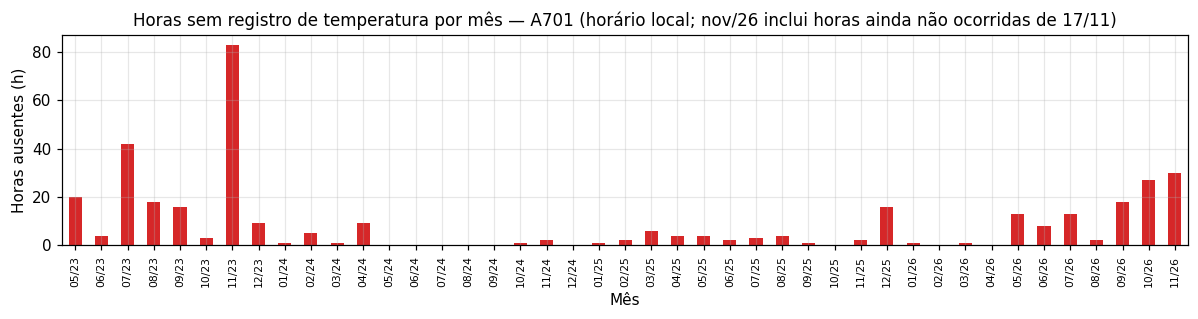

In [7]:
falta_h = horario.set_index("ts_local")["temp_ins"].isna().resample("MS").sum()
ax = falta_h.plot(kind="bar", figsize=(11, 3), color="tab:red")
ax.set_title("Horas sem registro de temperatura por mês — A701 (horário local; nov/26 inclui horas ainda não ocorridas de 17/11)")
ax.set_xlabel("Mês"); ax.set_ylabel("Horas ausentes (h)")
ax.set_xticklabels([d.strftime("%m/%y") for d in falta_h.index], rotation=90, fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "00_horas_ausentes_por_mes.png", dpi=150); plt.show()

## 3. Agregação diária (dia civil local)
| Variável diária | Origem horária | Regra |
|---|---|---|
| `tmax` | `Temp. Max. (C)` | máximo das máximas horárias |
| `tmin` | `Temp. Min. (C)` | mínimo das mínimas horárias |
| `tmean` | `Temp. Ins. (C)` | média das leituras horárias |
| `umi_min` / `umi_mean` | `Umi. Min. (%)` / `Umi. Ins. (%)` | mínimo / média |
| `chuva_mm` | `Chuva (mm)` | soma (inválida se < 18 h com chuva registrada) |
| `radiacao_mj` | `Radiacao (KJ/m²)` | soma ÷ 1000 (MJ/m²); lacuna noturna é normal; **inválida** se faltar radiação entre 10h–15h |
| `vento_mean` | `Vel. Vento (m/s)` | média |
| `pres_mean` | `Pressao Ins. (hPa)` | média (pressão ao nível da estação) |

**Critério de exclusão:** dia com **mais de 25% das horas ausentes** (menos de 18 de 24 horas com temperatura)
é marcado como inválido — não é preenchido.

In [8]:
r = relat["diario"]
print({k: v for k, v in r.items() if k != "datas_excluidas"})
print("Datas excluídas:", ", ".join(r["datas_excluidas"]))
diario.to_csv(PROC / "diario_a701.csv", float_format="%.4f")
pd.DataFrame({"ano": diario.index.year, "valido": diario["dia_valido"]}).groupby("ano").valido.agg(
    dias_validos="sum", dias_no_periodo="size")

{'dias_calendario': 1282, 'dias_validos': 1264, 'dias_excluidos_cobertura': 18, 'dias_radiacao_invalida': 10, 'dias_chuva_invalida': 20}
Datas excluídas: 2023-05-16, 2023-05-28, 2023-07-09, 2023-07-14, 2023-07-17, 2023-08-05, 2023-09-28, 2023-09-29, 2023-11-21, 2023-11-22, 2023-11-26, 2023-11-27, 2023-11-28, 2024-04-05, 2025-12-02, 2026-09-15, 2026-10-26, 2026-11-17


,dias_validos,dias_no_periodo
ano,,
2023,217,230
2024,365,366
2025,364,365
2026,318,321


In [9]:
diario.loc[diario.dia_valido, ["tmax", "tmin", "tmean", "umi_min", "umi_mean", "chuva_mm",
                               "radiacao_mj", "vento_mean", "pres_mean"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
tmax,1264.0,26.93,4.57,13.00,24.00,27.30,30.40,37.50
tmin,1264.0,16.84,3.11,5.70,14.70,17.00,19.30,24.10
tmean,1264.0,20.78,3.49,10.72,18.34,20.99,23.32,30.43
umi_min,1264.0,42.34,15.63,10.00,31.00,40.00,52.00,92.00
umi_mean,1264.0,68.18,11.23,28.33,61.61,69.25,76.09,94.08
chuva_mm,1244.0,4.18,10.82,0.00,0.00,0.00,1.80,125.60
radiacao_mj,1254.0,15.89,6.46,1.34,11.54,16.25,20.22,31.15
vento_mean,1264.0,1.71,0.59,0.11,1.31,1.66,2.06,6.11
pres_mean,1264.0,927.34,3.48,914.96,924.85,927.21,929.84,937.42


## 4. Engenharia de atributos
Para cada dia de referência **D** usamos somente informações de D, D‑1 e D‑2. Os deslocamentos são feitos por
**data de calendário** (índice diário contínuo): se D‑1 foi excluído, `tmax_d1` fica ausente — nunca “pula” para outro dia.

In [10]:
pd.DataFrame({"atributo": FEATURES, "descricao": [DESCRICAO_FEATURES[f] for f in FEATURES]})

,atributo,descricao
0,tmax_d0,Temperatura máxima do dia de referência (hoje)...
1,tmin_d0,"Temperatura mínima de hoje, °C"
2,tmean_d0,"Temperatura média horária de hoje, °C"
3,tmax_d1,"Temperatura máxima de ontem (D-1), °C"
4,tmean_d1,"Temperatura média de ontem (D-1), °C"
5,tmax_d2,"Temperatura máxima de anteontem (D-2), °C"
6,umi_min_d0,"Umidade relativa mínima de hoje, %"
7,umi_mean_d0,"Umidade relativa média de hoje, %"
8,chuva_d0,"Precipitação acumulada hoje, mm"
9,rad_d0,"Radiação solar global acumulada hoje, MJ/m²"


**Teste de vazamento:** alteramos artificialmente (só numa cópia) todos os dados a partir de D+1 e verificamos que
os atributos de D **não mudam**.

In [11]:
atrib = construir_atributos(diario)
D = pd.Timestamp("2025-01-15")
copia = diario.copy(); copia.loc[D + pd.Timedelta(days=1):, ["tmax", "tmin", "tmean", "umi_min"]] += 50
assert atrib.loc[D, FEATURES].equals(construir_atributos(copia).loc[D, FEATURES])
print("OK: atributos de", D.date(), "não dependem de D+1 ou posteriores.")
atrib.loc[D - pd.Timedelta(days=1): D + pd.Timedelta(days=1), FEATURES[:6]]

OK: atributos de 2025-01-15 não dependem de D+1 ou posteriores.


,tmax_d0,tmin_d0,tmean_d0,tmax_d1,tmean_d1,tmax_d2
data,,,,,,
2025-01-14,24.1,16.2,19.450000,24.8,20.250000,25.9
2025-01-15,29.2,18.4,22.420833,24.1,19.450000,24.8
2025-01-16,30.2,20.5,23.545833,29.2,22.420833,24.1


## 5. Variável‑alvo e divisão temporal
**Regra:** `extremo_amanha = 1` se **Tmax(D+1) ≥ P90** das Tmax diárias **do período de treino**; caso contrário 0.
O P90 é calculado **depois** da divisão e **somente** com o treino.

**Períodos (datas locais):**
* **Treino:** 17/05/2023 → 16/11/2025 (início real dos dados; abrange 2023, 2024 e 2025, incluindo os verões 23/24 e 24/25).
* **Teste:** 17/11/2025 → 16/11/2026 (um ciclo anual completo, verão 25/26; abrange 2025–2026).

Ajuste justificado: a série disponível começa em maio/2023, e um teste de exatamente 12 meses evita viés sazonal
nas métricas. Uma linha só entra num conjunto se **D e D+1** pertencem ao mesmo período (o último alvo de treino é
16/11/2025), garantindo que nenhum rótulo de treino use dados do teste. Linhas com atributo ou alvo ausente são
descartadas, sem imputação.

In [12]:
Xtr, ytr, Xte, yte, meta, tr, te = montar_conjuntos(diario)
LIMIAR = meta["limiar_p90_c"]
print(f"Limiar P90 (treino, {meta['n_dias_tmax_para_limiar']} dias válidos): {LIMIAR:.1f} °C")
pd.DataFrame([meta["treino"] | {"prevalencia_%": round(100 * ytr.mean(), 2)},
              meta["teste"] | {"prevalencia_%": round(100 * yte.mean(), 2)}], index=["treino", "teste"])

Limiar P90 (treino, 902 dias válidos): 32.9 °C


,inicio,fim_ref,fim_previsto,n,positivos,descartadas,prevalencia_%
treino,2023-05-19,2025-11-15,2025-11-16,846,88,68,10.40
teste,2025-11-17,2026-11-15,2026-11-16,349,21,15,6.02


In [13]:
assert Xtr.index.max() < Xte.index.min() and tr["data_prevista"].max() < Xte.index.min()
assert set(Xtr.index).isdisjoint(Xte.index)
print("OK: ordem cronológica preservada; treino termina antes do teste; nenhum alvo de treino cai no teste.")

OK: ordem cronológica preservada; treino termina antes do teste; nenhum alvo de treino cai no teste.


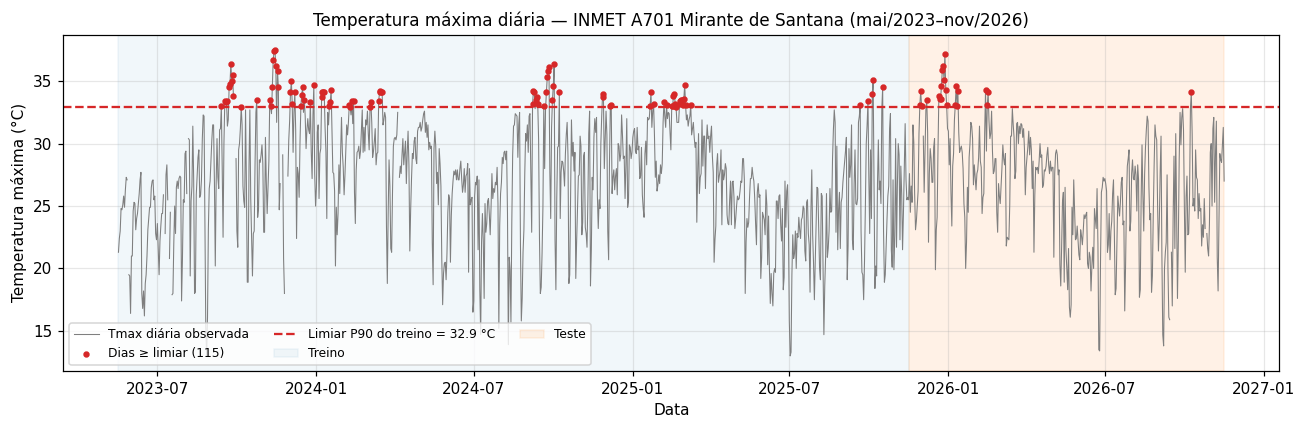

In [14]:
fig, ax = plt.subplots(figsize=(12, 4))
s = diario["tmax"]
ax.plot(s.index, s, lw=.7, color="tab:gray", label="Tmax diária observada")
ext = s[s >= LIMIAR]
ax.scatter(ext.index, ext, s=10, color="tab:red", zorder=3, label=f"Dias ≥ limiar ({len(ext)})")
ax.axhline(LIMIAR, color="tab:red", ls="--", label=f"Limiar P90 do treino = {LIMIAR:.1f} °C")
ax.axvspan(TREINO_INI, TREINO_FIM, color="tab:blue", alpha=.06, label="Treino")
ax.axvspan(TESTE_INI, TESTE_FIM, color="tab:orange", alpha=.10, label="Teste")
ax.set_title("Temperatura máxima diária — INMET A701 Mirante de Santana (mai/2023–nov/2026)")
ax.set_xlabel("Data"); ax.set_ylabel("Temperatura máxima (°C)"); ax.legend(loc="lower left", fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig(FIG / "01_serie_tmax_limiar.png", dpi=150); plt.show()

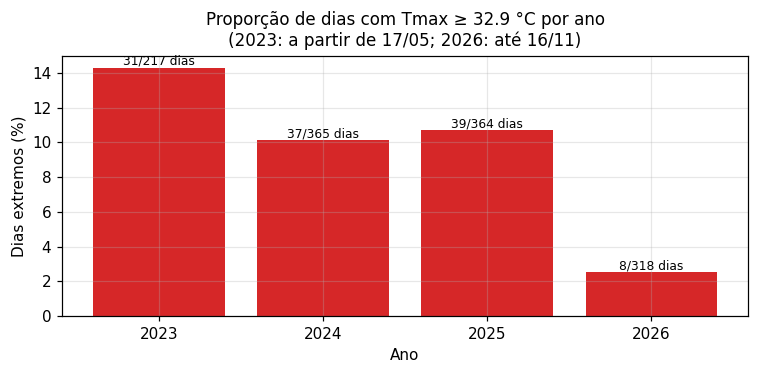

,proporcao,dias_extremos,dias_validos
data,,,
2023,0.143,31,217
2024,0.101,37,365
2025,0.107,39,364
2026,0.025,8,318


In [15]:
v = diario[diario.dia_valido]
prop = (v["tmax"] >= LIMIAR).groupby(v.index.year).agg(["mean", "sum", "size"])
fig, ax = plt.subplots(figsize=(7, 3.5))
b = ax.bar(prop.index.astype(str), 100 * prop["mean"], color="tab:red")
for rect, (_, row) in zip(b, prop.iterrows()):
    ax.annotate(f"{int(row['sum'])}/{int(row['size'])} dias", (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                ha="center", va="bottom", fontsize=8)
ax.set_title(f"Proporção de dias com Tmax ≥ {LIMIAR:.1f} °C por ano\n(2023: a partir de 17/05; 2026: até 16/11)")
ax.set_xlabel("Ano"); ax.set_ylabel("Dias extremos (%)")
plt.tight_layout(); plt.savefig(FIG / "02_proporcao_extremos_ano.png", dpi=150); plt.show()
prop.rename(columns={"mean": "proporcao", "sum": "dias_extremos", "size": "dias_validos"}).round(3)

## 6. Fase 3 — Random Forest + GridSearchCV com TimeSeriesSplit(5)
Validação cruzada **somente no treino**; `class_weight='balanced'` fixo; métrica de seleção: **F1 da classe 1**.
Grade: `n_estimators` {100, 300} × `max_depth` {5, 10, None} × `min_samples_leaf` {1, 5} = **12 combinações**.

In [16]:
tscv = TimeSeriesSplit(n_splits=5)
dobras = [{"dobra": i + 1, "treino": f"{Xtr.index[a][0].date()} → {Xtr.index[a][-1].date()}", "n_treino": len(a),
           "validacao": f"{Xtr.index[b][0].date()} → {Xtr.index[b][-1].date()}", "n_val": len(b),
           "positivos_val": int(ytr.iloc[b].sum())} for i, (a, b) in enumerate(tscv.split(Xtr))]
pd.DataFrame(dobras)

,dobra,treino,n_treino,validacao,n_val,positivos_val
0,1,2023-05-19 → 2023-11-19,141,2023-12-01 → 2024-04-27,141,26
1,2,2023-05-19 → 2024-04-27,282,2024-04-28 → 2024-09-15,141,6
2,3,2023-05-19 → 2024-09-15,423,2024-09-16 → 2025-02-05,141,16
3,4,2023-05-19 → 2025-02-05,564,2025-02-06 → 2025-06-27,141,15
4,5,2023-05-19 → 2025-06-27,705,2025-06-28 → 2025-11-15,141,5


In [17]:
gs = GridSearchCV(novo_rf(), PARAM_GRID, cv=tscv, scoring="f1", return_train_score=True, n_jobs=1, refit=True)
gs.fit(Xtr, ytr)
cv = pd.DataFrame(gs.cv_results_)
tab = pd.DataFrame({
    "n_estimators": cv["param_n_estimators"], "max_depth": cv["param_max_depth"].astype(str),
    "min_samples_leaf": cv["param_min_samples_leaf"],
    "F1_val_media": cv["mean_test_score"].round(4), "F1_val_desvio": cv["std_test_score"].round(4),
    "F1_treino_dobras": cv["mean_train_score"].round(4), "rank": cv["rank_test_score"]})
for i in range(5): tab[f"F1_d{i+1}"] = cv[f"split{i}_test_score"].round(3)
assert len(tab) == 12
tab.sort_values("rank").to_csv(REP / "gridsearch_12_combinacoes.csv", index=False)
print("Melhor configuração:", gs.best_params_, "| F1 médio CV =", round(gs.best_score_, 4))
tab.sort_values("rank")

Melhor configuração: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 300} | F1 médio CV = 0.5526


,n_estimators,max_depth,min_samples_leaf,F1_val_media,F1_val_desvio,F1_treino_dobras,rank,F1_d1,F1_d2,F1_d3,F1_d4,F1_d5
11,300,None,5,0.5526,0.0618,0.7751,1,0.613,0.533,0.512,0.634,0.471
7,300,10,5,0.5474,0.0692,0.7739,2,0.613,0.533,0.512,0.634,0.444
6,100,10,5,0.5377,0.0836,0.7681,3,0.590,0.533,0.455,0.667,0.444
10,100,None,5,0.5377,0.0836,0.7657,3,0.590,0.533,0.455,0.667,0.444
3,300,5,5,0.5353,0.0800,0.7352,5,0.613,0.533,0.511,0.619,0.400
1,300,5,1,0.5052,0.0740,0.7986,6,0.548,0.400,0.488,0.619,0.471
2,100,5,5,0.5028,0.0923,0.7303,7,0.590,0.429,0.462,0.634,0.400
0,100,5,1,0.4629,0.1623,0.8021,8,0.625,0.222,0.500,0.634,0.333
4,100,10,1,0.4566,0.0980,0.9609,9,0.480,0.286,0.485,0.588,0.444
8,100,None,1,0.3855,0.2200,1.0000,10,0.490,0.286,0.571,0.581,0.000


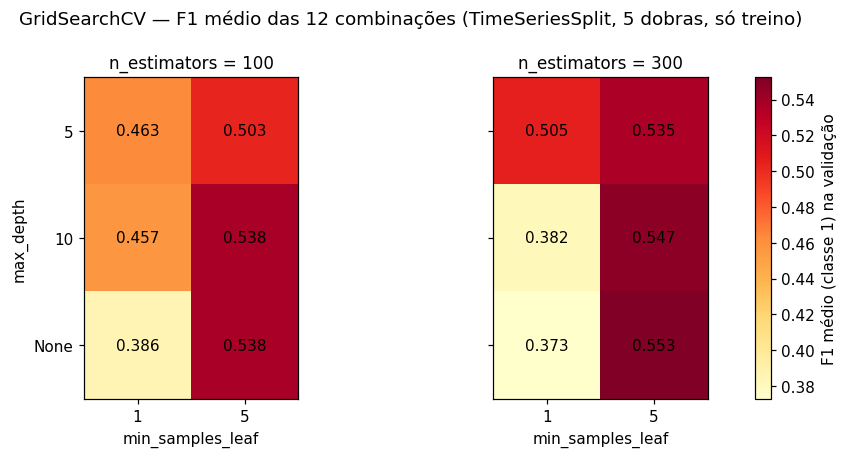

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ne in zip(axs, [100, 300]):
    piv = tab[tab.n_estimators == ne].pivot(index="max_depth", columns="min_samples_leaf", values="F1_val_media")
    piv = piv.loc[["5", "10", "None"]]
    im = ax.imshow(piv.values, cmap="YlOrRd", vmin=tab.F1_val_media.min(), vmax=tab.F1_val_media.max())
    for (i, j), val in np.ndenumerate(piv.values):
        ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=10)
    ax.set_xticks(range(2), piv.columns); ax.set_yticks(range(3), piv.index)
    ax.set_xlabel("min_samples_leaf"); ax.set_title(f"n_estimators = {ne}"); ax.grid(False)
axs[0].set_ylabel("max_depth")
fig.colorbar(im, ax=axs, label="F1 médio (classe 1) na validação")
fig.suptitle("GridSearchCV — F1 médio das 12 combinações (TimeSeriesSplit, 5 dobras, só treino)", y=1.04)
plt.savefig(FIG / "03_heatmap_hiperparametros.png", dpi=150, bbox_inches="tight"); plt.show()

**Profundidade × overfitting (na validação cruzada):** com `min_samples_leaf=1`, árvores mais profundas
(`10`/`None`) atingem F1 de treino ≈ 0,96–1,00 mas F1 de validação **cai** — memorizam o treino.
Folhas com ≥ 5 amostras regularizam as árvores e dão o melhor F1 de validação.

In [19]:
prof = tab.groupby(["max_depth", "min_samples_leaf"])[["F1_treino_dobras", "F1_val_media"]].mean().round(3)
prof["gap"] = (prof["F1_treino_dobras"] - prof["F1_val_media"]).round(3); prof

F1_treino_dobras  F1_val_media    gap
max_depth min_samples_leaf                                       
10        1                            0.964         0.419  0.545
          5                            0.771         0.543  0.228
5         1                            0.800         0.484  0.316
          5                            0.733         0.519  0.214
None      1                            1.000         0.379  0.621
          5                            0.770         0.545  0.225

**Escolha:** a configuração de maior F1 médio na validação. Desvio‑padrão entre dobras é alto porque cada dobra cobre
~5 meses e o número de dias extremos varia muito com a estação (5 a 26 positivos). O conjunto de teste **não** foi usado.
O `GridSearchCV(refit=True)` retreina a configuração vencedora com **todo** o treino.

In [20]:
best = gs.best_params_
modelo = gs.best_estimator_
print(modelo)

RandomForestClassifier(class_weight='balanced', min_samples_leaf=5,
                       n_estimators=300, n_jobs=-1, random_state=42)


### 6.1 Limiar de decisão (escolhido sem tocar no teste)
Geramos probabilidades **fora da amostra** nas 5 dobras do `TimeSeriesSplit` (só treino) com a configuração vencedora
e analisamos a curva Precision‑Recall. **Regra:** maior limiar que mantém **Recall ≥ 0,80** (meta do projeto) —
perder um dia extremo (falso negativo) é mais grave para o cidadão que um alerta a mais.

In [21]:
oof = probas_oof(best, Xtr, ytr)
y_oof = ytr.loc[oof.index]
P, R, T = precision_recall_curve(y_oof, oof)
ok = np.where(R[:-1] >= 0.80)[0]
LIMIAR_DECISAO = float(np.floor(T[ok].max() * 100) / 100)  # arredonda para baixo: preserva Recall ≥ 0,80
grade_t = []
for t in [0.2, 0.3, 0.4, 0.5, 0.51, LIMIAR_DECISAO, 0.6, 0.7]:
    m = metricas(y_oof, (oof >= t).astype(int), oof)
    grade_t.append({"limiar": t, "precision_oof": m["precision"], "recall_oof": m["recall"], "f1_oof": m["f1"]})
print(f"OOF: {len(oof)} dias, {int(y_oof.sum())} extremos. Limiar escolhido = {LIMIAR_DECISAO:.2f}")
pd.DataFrame(grade_t).drop_duplicates("limiar").sort_values("limiar")

OOF: 705 dias, 68 extremos. Limiar escolhido = 0.51


,limiar,precision_oof,recall_oof,f1_oof
0,0.20,0.2471,0.9265,0.3901
1,0.30,0.3229,0.9118,0.4769
2,0.40,0.3882,0.8676,0.5364
3,0.50,0.4472,0.8088,0.5759
4,0.51,0.4661,0.8088,0.5914
6,0.60,0.4831,0.6324,0.5478
7,0.70,0.4821,0.3971,0.4355


## 7. Fase 4 — Avaliação: treino × teste e baselines
* **RF – treino:** modelo final avaliado no próprio treino (in‑sample).
* **RF – CV:** média das dobras (estimativa honesta dentro do treino).
* **RF – teste:** período isolado (17/11/2025 → 16/11/2026).
* **Persistência:** prevê extremo amanhã se hoje já foi extremo (Tmax ≥ limiar do treino).
* **Climatológico:** prevê sempre a classe mais frequente do treino (0).

In [22]:
p_tr, p_te = modelo.predict_proba(Xtr)[:, 1], modelo.predict_proba(Xte)[:, 1]
yhat_tr, yhat_te = (p_tr >= LIMIAR_DECISAO).astype(int), (p_te >= LIMIAR_DECISAO).astype(int)
res = {
    "RF – treino": metricas(ytr, yhat_tr, p_tr),
    "RF – teste": metricas(yte, yhat_te, p_te),
    "Persistência – teste": metricas(yte, baseline_persistencia(te)),
    "Climatológico – teste": metricas(yte, baseline_climatologico(ytr, len(yte)), np.zeros(len(yte))),
    "Persistência – treino": metricas(ytr, baseline_persistencia(tr)),
    "RF – teste (limiar 0,50)": metricas(yte, (p_te >= .5).astype(int), p_te),
}
resultados = pd.DataFrame(res).T
resultados

,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
RF – treino,0.9409,0.6484,0.9432,0.7685,0.9887,0.9183,713.0,45.0,5.0,83.0
RF – teste,0.9570,0.6071,0.8095,0.6939,0.9662,0.7823,317.0,11.0,4.0,17.0
Persistência – teste,0.9656,0.7143,0.7143,0.7143,0.8480,0.5274,322.0,6.0,6.0,15.0
Climatológico – teste,0.9398,0.0000,0.0000,0.0000,0.5000,0.0602,328.0,0.0,21.0,0.0
Persistência – treino,0.9113,0.5730,0.5795,0.5763,0.7647,0.3758,720.0,38.0,37.0,51.0
"RF – teste (limiar 0,50)",0.9570,0.6071,0.8095,0.6939,0.9662,0.7823,317.0,11.0,4.0,17.0


In [23]:
f1_tr, f1_te = res["RF – treino"]["f1"], res["RF – teste"]["f1"]
gap = round(f1_tr - f1_te, 4)
print(f"F1 treino = {f1_tr:.4f} | F1 teste = {f1_te:.4f} | diferença = {gap:.4f} ->",
      "ALERTA de overfitting (> 0,10)" if gap > 0.10 else "dentro do limite de 0,10")
print(f"F1 médio CV (validação) da configuração escolhida = {gs.best_score_:.4f}")

F1 treino = 0.7685 | F1 teste = 0.6939 | diferença = 0.0746 -> dentro do limite de 0,10
F1 médio CV (validação) da configuração escolhida = 0.5526


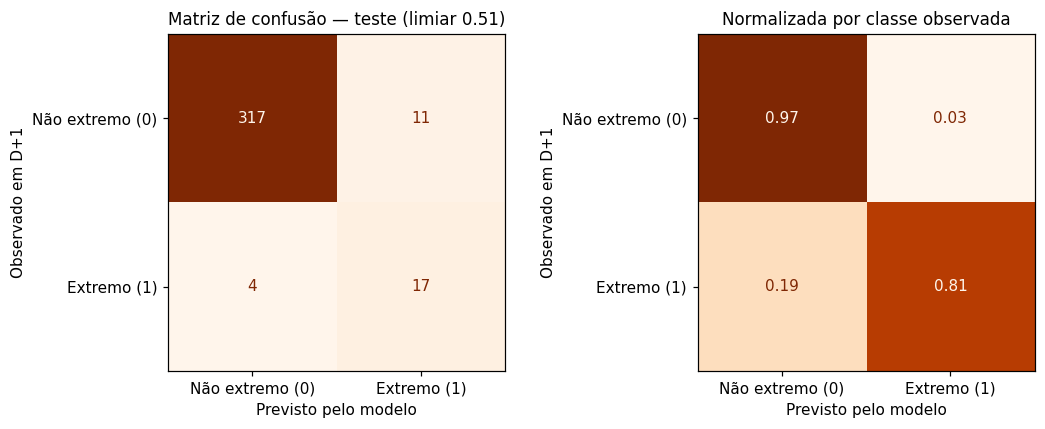

VP=17  VN=317  FP=11  FN=4


In [24]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
cm = np.array([[res["RF – teste"]["tn"], res["RF – teste"]["fp"]], [res["RF – teste"]["fn"], res["RF – teste"]["tp"]]])
ConfusionMatrixDisplay(cm, display_labels=["Não extremo (0)", "Extremo (1)"]).plot(ax=axs[0], cmap="Oranges", colorbar=False)
axs[0].set_title(f"Matriz de confusão — teste (limiar {LIMIAR_DECISAO:.2f})"); axs[0].grid(False)
axs[0].set_xlabel("Previsto pelo modelo"); axs[0].set_ylabel("Observado em D+1")
cmn = cm / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cmn, display_labels=["Não extremo (0)", "Extremo (1)"]).plot(ax=axs[1], cmap="Oranges", colorbar=False, values_format=".2f")
axs[1].set_title("Normalizada por classe observada"); axs[1].grid(False)
axs[1].set_xlabel("Previsto pelo modelo"); axs[1].set_ylabel("Observado em D+1")
plt.tight_layout(); plt.savefig(FIG / "04_matriz_confusao_teste.png", dpi=150); plt.show()
print(f"VP={cm[1,1]}  VN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}")

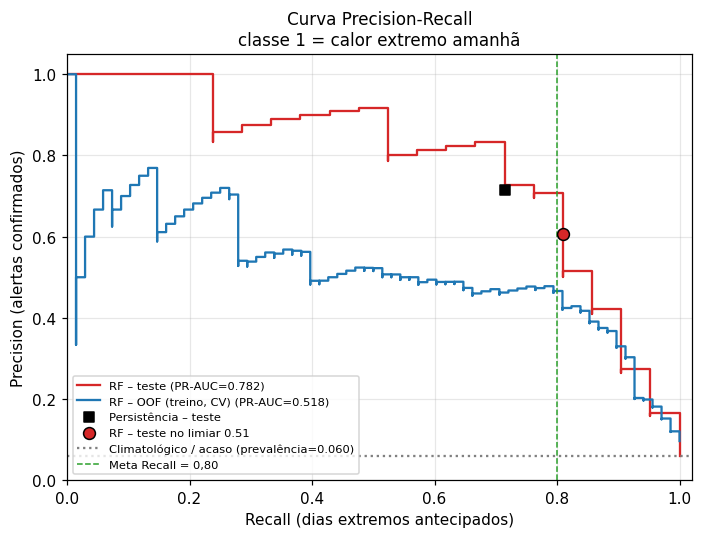

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for nome, y_, p_, cor in [("RF – teste", yte, p_te, "tab:red"), ("RF – OOF (treino, CV)", y_oof, oof, "tab:blue")]:
    pp, rr, _ = precision_recall_curve(y_, p_)
    ax.step(rr, pp, where="post", color=cor, label=f"{nome} (PR‑AUC={metricas(y_, (p_>=.5).astype(int), p_)['pr_auc']:.3f})")
pr = res["Persistência – teste"]
ax.scatter(pr["recall"], pr["precision"], marker="s", color="k", zorder=3, label="Persistência – teste")
rt = res["RF – teste"]
ax.scatter(rt["recall"], rt["precision"], marker="o", s=60, color="tab:red", edgecolor="k", zorder=4,
           label=f"RF – teste no limiar {LIMIAR_DECISAO:.2f}")
ax.axhline(yte.mean(), color="gray", ls=":", label=f"Climatológico / acaso (prevalência={yte.mean():.3f})")
ax.axvline(0.80, color="tab:green", ls="--", lw=1, label="Meta Recall = 0,80")
ax.set_xlabel("Recall (dias extremos antecipados)"); ax.set_ylabel("Precision (alertas confirmados)")
ax.set_title("Curva Precision‑Recall\nclasse 1 = calor extremo amanhã"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
ax.legend(fontsize=7.5, loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "05_curva_precision_recall.png", dpi=150); plt.show()

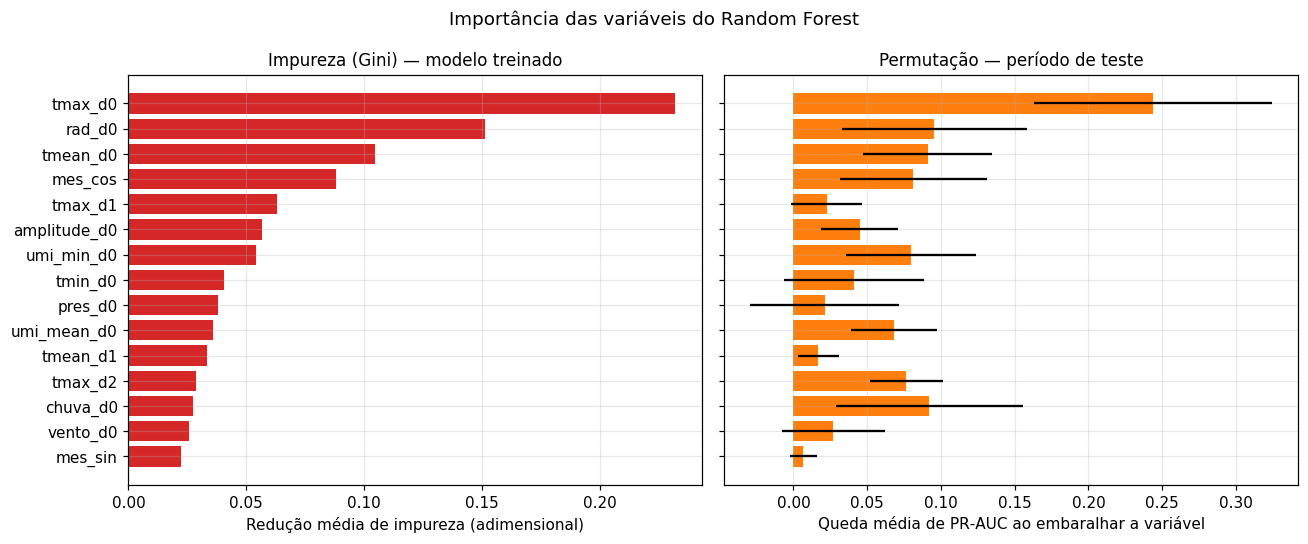

,gini,permutacao_teste
tmax_d0,0.2317,0.2438
rad_d0,0.1512,0.0953
tmean_d0,0.1047,0.0910
mes_cos,0.0879,0.0812
tmax_d1,0.0629,0.0225
amplitude_d0,0.0567,0.0448
umi_min_d0,0.0539,0.0795
tmin_d0,0.0404,0.0409
pres_d0,0.0378,0.0211
umi_mean_d0,0.0357,0.0683


In [26]:
imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
perm = permutation_importance(modelo, Xte, yte, scoring="average_precision", n_repeats=30, random_state=SEED)
perm_s = pd.Series(perm.importances_mean, index=FEATURES).reindex(imp.index)
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axs[0].barh(imp.index, imp.values, color="tab:red"); axs[0].set_title("Impureza (Gini) — modelo treinado")
axs[0].set_xlabel("Redução média de impureza (adimensional)")
axs[1].barh(perm_s.index, perm_s.values, xerr=pd.Series(perm.importances_std, index=FEATURES).reindex(imp.index),
            color="tab:orange"); axs[1].set_title("Permutação — período de teste")
axs[1].set_xlabel("Queda média de PR‑AUC ao embaralhar a variável")
fig.suptitle("Importância das variáveis do Random Forest")
plt.tight_layout(); plt.savefig(FIG / "06_importancia_variaveis.png", dpi=150); plt.show()
pd.DataFrame({"gini": imp, "permutacao_teste": perm_s}).sort_values("gini", ascending=False).round(4)

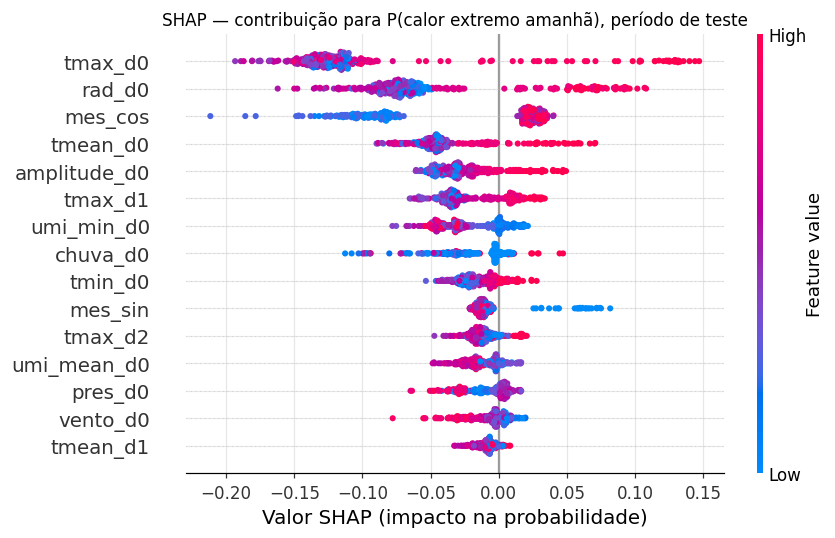

SHAP versão 0.49.1
tmax_d0         0.1201
rad_d0          0.0723
mes_cos         0.0572
tmean_d0        0.0441
amplitude_d0    0.0299
tmax_d1         0.0278
umi_min_d0      0.0252
chuva_d0        0.0209
dtype: float64


In [27]:
try:
    warnings.filterwarnings("ignore")
    import shap
    expl = shap.TreeExplainer(modelo)
    sv = expl.shap_values(Xte)
    sv1 = sv[:, :, 1] if np.ndim(sv) == 3 else sv[1]
    plt.figure()
    shap.summary_plot(sv1, Xte, show=False, plot_size=(8, 5))
    plt.title("SHAP — contribuição para P(calor extremo amanhã), período de teste"); plt.xlabel("Valor SHAP (impacto na probabilidade)")
    plt.tight_layout(); plt.savefig(FIG / "06b_shap_resumo.png", dpi=150); plt.show()
    shap_rank = pd.Series(np.abs(sv1).mean(0), index=FEATURES).sort_values(ascending=False).round(4)
    print("SHAP versão", shap.__version__); print(shap_rank.head(8))
except Exception as e:
    shap_rank = None; print("SHAP não executado:", e)

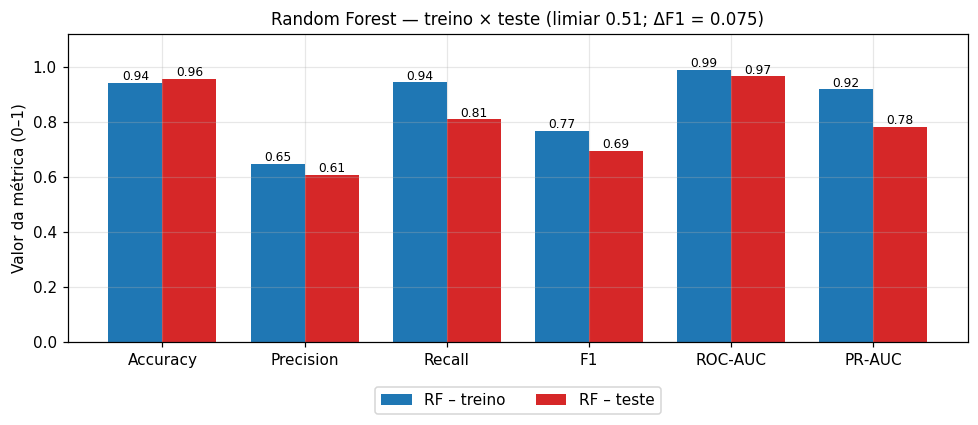

In [28]:
mets = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(mets)); w = .38
for k, (nome, cor) in enumerate([("RF – treino", "tab:blue"), ("RF – teste", "tab:red")]):
    vals = [res[nome][m] for m in mets]
    bb = ax.bar(x + (k - .5) * w, vals, w, label=nome, color=cor)
    ax.bar_label(bb, fmt="%.2f", fontsize=8)
ax.set_xticks(x, ["Accuracy", "Precision", "Recall", "F1", "ROC‑AUC", "PR‑AUC"]); ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor da métrica (0–1)"); ax.set_title(f"Random Forest — treino × teste (limiar {LIMIAR_DECISAO:.2f}; ΔF1 = {gap:.3f})")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2); plt.tight_layout(); plt.savefig(FIG / "07_treino_vs_teste.png", dpi=150); plt.show()

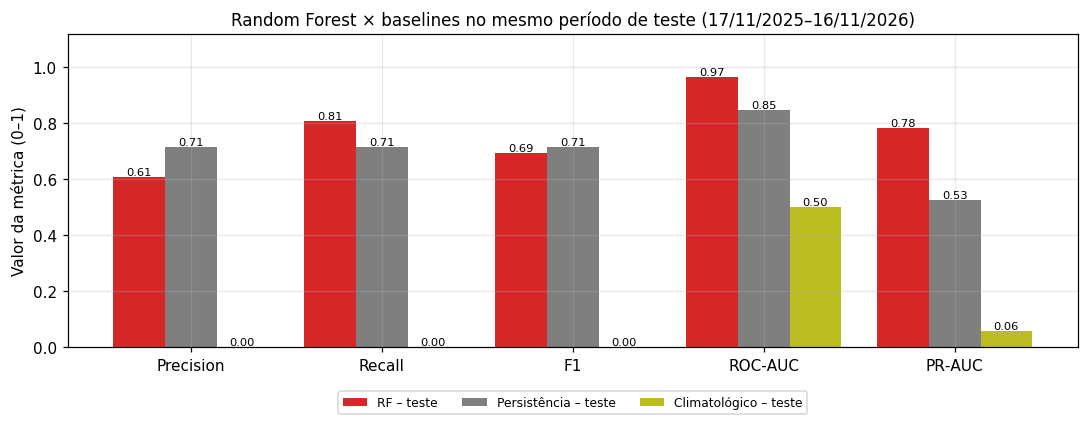

In [29]:
comp = ["RF – teste", "Persistência – teste", "Climatológico – teste"]
mets2 = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
fig, ax = plt.subplots(figsize=(10, 4)); w = .27
for k, (nome, cor) in enumerate(zip(comp, ["tab:red", "tab:gray", "tab:olive"])):
    bb = ax.bar(np.arange(len(mets2)) + (k - 1) * w, [res[nome].get(m, np.nan) for m in mets2], w, label=nome, color=cor)
    ax.bar_label(bb, fmt="%.2f", fontsize=7.5)
ax.set_xticks(range(len(mets2)), ["Precision", "Recall", "F1", "ROC‑AUC", "PR‑AUC"]); ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor da métrica (0–1)"); ax.set_title("Random Forest × baselines no mesmo período de teste (17/11/2025–16/11/2026)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3); plt.tight_layout(); plt.savefig(FIG / "08_rf_vs_baselines.png", dpi=150); plt.show()

## 8. Erros do modelo no teste — quem foi afetado?
Listamos os falsos negativos (dia extremo **não** antecipado) e os falsos positivos (alerta sem calor extremo).

In [30]:
det = te[["data_prevista", "tmax_d0"]].copy()
det["tmax_amanha_obs"] = diario["tmax"].reindex(det["data_prevista"]).to_numpy()
det["prob"] = p_te.round(3); det["previsto"] = yhat_te; det["observado"] = yte.to_numpy()
fn_ = det[(det.observado == 1) & (det.previsto == 0)]; fp_ = det[(det.observado == 0) & (det.previsto == 1)]
print("Falsos negativos (dias extremos perdidos):"); display(fn_)
print("Falsos positivos (alertas não confirmados) — Tmax observada no dia alertado:")
display(fp_.describe().loc[["count", "mean", "min", "max"], ["tmax_amanha_obs", "prob"]].round(2))

Falsos negativos (dias extremos perdidos):


,data_prevista,tmax_d0,tmax_amanha_obs,prob,previsto,observado
data,,,,,,
2025-11-28,2025-11-29,30.8,33.1,0.324,0,1
2025-12-20,2025-12-21,29.6,33.8,0.206,0,1
2026-01-08,2026-01-09,31.9,33.1,0.423,0,1
2026-02-14,2026-02-15,29.4,33.1,0.070,0,1


Falsos positivos (alertas não confirmados) — Tmax observada no dia alertado:


,tmax_amanha_obs,prob
count,11.00,11.00
mean,30.65,0.67
min,29.40,0.51
max,31.80,0.80


## 9. Tradução para o cidadão e níveis de alerta

In [31]:
rt = res["RF – teste"]
X10 = 10 * rt["recall"]; Y10 = 10 * rt["precision"]
print(f"De cada 10 dias de calor extremo no período de teste, o Sereno SP antecipou {X10:.1f} "
      f"({rt['tp']} de {rt['tp'] + rt['fn']}).")
print(f"De cada 10 alertas emitidos, {Y10:.1f} foram confirmados ({rt['tp']} de {rt['tp'] + rt['fp']}).")
print(f"Meta de Recall ≥ 0,80: {'atingida' if rt['recall'] >= .8 else 'NÃO atingida'} (Recall = {rt['recall']:.3f}).")
niv = pd.Series([nivel_alerta(p) for p in p_te], index=Xte.index)
tabn = pd.crosstab(niv, yte.rename("observado_extremo"), margins=True).reindex(["Perigo", "Atencao", "SemAlerta", "All"])
tabn["taxa_confirmacao_%"] = (100 * tabn.get(1, 0) / tabn["All"]).round(1)
tabn

De cada 10 dias de calor extremo no período de teste, o Sereno SP antecipou 8.1 (17 de 21).
De cada 10 alertas emitidos, 6.1 foram confirmados (17 de 28).
Meta de Recall ≥ 0,80: atingida (Recall = 0.809).


observado_extremo,0,1,All,taxa_confirmacao_%
row_0,,,,
Perigo,5,15,20,75.0
Atencao,13,3,16,18.8
SemAlerta,310,3,313,1.0
All,328,21,349,6.0


## 10. Fase 5 — Serialização do modelo e integração
O pacote salvo contém o modelo, a lista ordenada de atributos, o limiar P90 (°C), o limiar de decisão, os níveis
de comunicação e os metadados de treino. O script `predict_publish.py` usa esse pacote.

In [32]:
VERSAO = "sereno-rf-1.0"
bundle = {"modelo": modelo, "features": FEATURES, "limiar_calor_c": LIMIAR, "limiar_decisao": LIMIAR_DECISAO,
          "niveis": {"Perigo": "> 0.70", "Atencao": "0.40 – 0.70", "SemAlerta": "< 0.40"},
          "versao": VERSAO, "hiperparametros": best, "treino": meta["treino"], "teste": meta["teste"],
          "sklearn": sklearn.__version__, "estacao": "A701"}
joblib.dump(bundle, MOD / "sereno_rf.joblib", compress=3)
rec = joblib.load(MOD / "sereno_rf.joblib")
assert np.allclose(rec["modelo"].predict_proba(Xte)[:, 1], p_te)
print("Modelo salvo e recarregado com previsões idênticas:", MOD / "sereno_rf.joblib")

relatorio = {"versao": VERSAO, "fonte": "INMET Tabela de Dados das Estações — A701", "limpeza": relat,
             "split": meta, "limiar_p90_c": LIMIAR, "limiar_decisao": LIMIAR_DECISAO, "melhor_config": best,
             "melhor_f1_cv": round(gs.best_score_, 4), "dobras": dobras, "metricas": res, "gap_f1": gap,
             "importancia_gini": imp.sort_values(ascending=False).round(4).to_dict(),
             "importancia_perm": perm_s.sort_values(ascending=False).round(4).to_dict(),
             "shap": None if shap_rank is None else shap_rank.to_dict(),
             "limiares_oof": grade_t, "niveis_teste": tabn.fillna(0).to_dict(),
             "falsos_negativos": fn_.reset_index().astype(str).to_dict("records")}
(REP / "metricas.json").write_text(json.dumps(relatorio, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
resultados.to_csv(REP / "metricas_treino_teste_baselines.csv")
print("Relatórios salvos em", REP)

Modelo salvo e recarregado com previsões idênticas: models/sereno_rf.joblib
Relatórios salvos em reports


### 10.1 Demonstração do **modo replay** (retrospectivo — NÃO é previsão operacional)
Reproduz o que o Sereno SP teria publicado na véspera, usando dados já observados do período de teste.
Em `--dry-run` o JSON é apenas exibido (nenhum envio à API).

In [33]:
import subprocess, sys
out = subprocess.run([sys.executable, "predict_publish.py", "--replay", "2025-12-24", "--dry-run"],
                     capture_output=True, text=True)
print(out.stdout); print(out.stderr[-800:])

{
  "dataReferencia": "2025-12-25",
  "dataBase": "2025-12-24",
  "probabilidade": 0.8838,
  "nivel": "Perigo",
  "alertaExtremo": true,
  "limiarCalorC": 32.9,
  "versaoModelo": "sereno-rf-1.0",
  "estacao": "A701",
  "modo": "replay",
  "geradoEm": "2026-11-17T17:07:51+00:00",
  "observacao": "Demonstração retrospectiva com dados históricos do INMET; não é previsão meteorológica operacional."
}

2026-11-17 14:07:51,693 INFO sereno.predict_publish: [REPLAY] Tmax observada em 2025-12-25: 35.9 °C (limiar 32.9 °C).
2026-11-17 14:07:51,712 INFO sereno.predict_publish: --dry-run: nada foi enviado.



## 11. Conclusão
Os números finais, a comparação com baselines e as limitações estão consolidados em `RELATORIO_ML.md`, escrito a
partir de `reports/metricas.json` gerado por esta execução.